# Step 5 — Model Probabilistik: Okapi BM25

**Tujuan praktikum**
1. Mahasiswa memahami ide model probabilistik dan fungsi pemeringkatan BM25.
2. Mahasiswa mampu mengimplementasikan BM25 dengan parameter $k_1$ dan $b$.
3. Mahasiswa mampu menganalisis pengaruh saturasi TF dan normalisasi panjang dokumen.

**Rumus BM25**

$$\text{score}(q,d) = \sum_{t \in q} \text{IDF}(t) \cdot \frac{tf_{t,d}\,(k_1+1)}{tf_{t,d} + k_1\left(1 - b + b\,\frac{|d|}{avgdl}\right)}$$

$$\text{IDF}(t) = \ln\left(1 + \frac{N - df_t + 0.5}{df_t + 0.5}\right)$$

In [3]:
# Jalankan sekali jika pustaka belum terpasang:
# !pip install pandas numpy matplotlib Sastrawi
import pandas as pd
pd.set_option("display.max_colwidth", 120)

In [1]:
import math
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
from stki_utils import corpus_texts, preprocess, build_inverted_index, load_corpus, TfidfModel

judul = dict(zip(load_corpus().doc_id, load_corpus().judul))
docs = {d: preprocess(t) for d, t in corpus_texts().items()}
index = build_inverted_index(docs)
N = len(docs)
doc_len = {d: len(t) for d, t in docs.items()}
avgdl = sum(doc_len.values()) / N
print(f"N = {N}, avgdl = {avgdl:.2f}, dokumen terpendek = {min(doc_len.values())}, terpanjang = {max(doc_len.values())}")

N = 30, avgdl = 28.77, dokumen terpendek = 25, terpanjang = 38


## Langkah 1 — Implementasi BM25

In [4]:
def bm25_idf(term):
    df = len(index.get(term, {}))
    return math.log(1 + (N - df + 0.5) / (df + 0.5))

def bm25_score(q_tokens, doc_id, k1=1.5, b=0.75):
    skor = 0.0
    for t in q_tokens:
        tf = index.get(t, {}).get(doc_id, 0)
        if tf:
            norm = k1 * (1 - b + b * doc_len[doc_id] / avgdl)
            skor += bm25_idf(t) * tf * (k1 + 1) / (tf + norm)
    return skor

def bm25_search(query, k=5, k1=1.5, b=0.75):
    q = preprocess(query)
    kandidat = {d for t in q for d in index.get(t, {})}
    skor = {d: bm25_score(q, d, k1, b) for d in kandidat}
    return sorted(skor.items(), key=lambda x: (-x[1], x[0]))[:k]

hasil = bm25_search("harga hasil panen petani")
pd.DataFrame([(d, judul[d], round(s, 4)) for d, s in hasil], columns=["doc_id", "judul", "BM25"])

,doc_id,judul,BM25
0,D12,Harga Gabah Saat Panen Raya,9.5757
1,D07,Budidaya Padi Sawah,6.2919
2,D23,Ekspor Kopi Nusantara,3.6440
3,D20,Memahami Inflasi,3.1788
4,D10,Pertanian Cerdas Berbasis IoT,2.3401


In [5]:
from stki_utils import BM25Model

model = BM25Model(docs)
print("Sama dengan stki_utils.BM25Model:",
      [d for d, _ in model.search(preprocess("harga hasil panen petani"), 5)] == [d for d, _ in hasil])

Sama dengan stki_utils.BM25Model: True


## Langkah 2 — Saturasi term frequency ($k_1$)
Pada TF-IDF, kontribusi TF terus naik. Pada BM25, kontribusi TF mendekati batas atas $k_1 + 1$, sehingga dokumen yang mengulang-ulang satu kata tidak mendapat skor berlebihan.

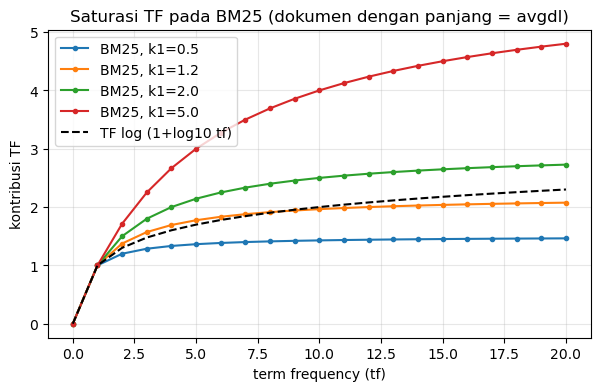

In [6]:
tf = list(range(0, 21))
plt.figure(figsize=(7, 4))
for k1 in [0.5, 1.2, 2.0, 5.0]:
    plt.plot(tf, [x * (k1 + 1) / (x + k1) for x in tf], marker=".", label=f"BM25, k1={k1}")
plt.plot(tf, [1 + math.log10(x) if x else 0 for x in tf], "k--", label="TF log (1+log10 tf)")
plt.xlabel("term frequency (tf)"); plt.ylabel("kontribusi TF")
plt.title("Saturasi TF pada BM25 (dokumen dengan panjang = avgdl)")
plt.legend(); plt.grid(alpha=.3); plt.show()

## Langkah 3 — Normalisasi panjang dokumen ($b$)
$b = 0$ berarti panjang dokumen diabaikan; $b = 1$ berarti normalisasi penuh.

In [7]:
query = "keamanan data pribadi di internet"
tabel = {}
for b in [0.0, 0.5, 0.75, 1.0]:
    tabel[f"b={b}"] = [f"{d} ({s:.2f})" for d, s in bm25_search(query, k=5, b=b)]
pd.DataFrame(tabel, index=range(1, 6))

,b=0.0,b=0.5,b=0.75,b=1.0
1,D15 (6.77),D15 (6.76),D15 (6.75),D15 (6.74)
2,D06 (3.74),D06 (3.90),D06 (3.98),D06 (4.06)
3,D10 (3.74),D16 (3.85),D16 (3.91),D16 (3.97)
4,D16 (3.74),D10 (3.70),D10 (3.67),D10 (3.65)
5,D25 (3.12),D25 (3.13),D25 (3.14),D25 (3.15)


## Langkah 4 — Membandingkan TF-IDF dan BM25

In [8]:
tfidf = TfidfModel(docs)
for q in ["teknologi pertanian modern", "pemasaran digital UMKM", "keamanan data pribadi di internet"]:
    a = [d for d, _ in tfidf.search(preprocess(q), 5)]
    b = [d for d, _ in model.search(preprocess(q), 5)]
    print(f"{q}\n  TF-IDF: {a}\n  BM25  : {b}\n")

teknologi pertanian modern
  TF-IDF: ['D10', 'D06', 'D27', 'D12', 'D08']
  BM25  : ['D10', 'D12', 'D06', 'D27', 'D08']

pemasaran digital UMKM
  TF-IDF: ['D19', 'D22', 'D24', 'D27', 'D21']
  BM25  : ['D19', 'D22', 'D21', 'D27', 'D29']

keamanan data pribadi di internet
  TF-IDF: ['D15', 'D06', 'D16', 'D10', 'D25']
  BM25  : ['D15', 'D06', 'D16', 'D10', 'D25']



## Tugas Step 5
1. Lakukan *grid search* $k_1 \in \{0.5, 1.0, 1.2, 1.5, 2.0\}$ dan $b \in \{0, 0.25, 0.5, 0.75, 1.0\}$. Simpan kombinasi yang menghasilkan MAP terbaik (gunakan fungsi evaluasi dari Step 6).
2. Buat satu dokumen buatan yang sangat panjang dan mengulang kata `tani` 20 kali. Tambahkan ke korpus, lalu bandingkan peringkatnya pada TF-IDF dan BM25 untuk query `tani`. Jelaskan.

In [8]:
# Tulis jawaban Anda di sini